# EchoMind — UrbanSound8K: Full Training & Evaluation Pipeline

**الهدف:** تنزيل وفحص UrbanSound8K، تقسيمه حسب الـ folds الرسمية، استخراج الخصائص الصوتية باستخدام YAMNet، ثم **تدريب SVM وMLP فعليًا** على بيانات التدريب، اختيار النموذج على validation، وتقييم نهائي على test، مع تقارير ورسوم وحفظ النماذج.

> هذا Notebook للتدريب والتقييم الكامل، وليس مجرد واجهة ترفع لها صوتًا. واجهة تجربة صوت جديد موجودة في آخر جزء كميزة إضافية فقط.

## 1) إعداد بيئة العمل

شغّل الخلايا بالترتيب في Google Colab. يفضّل Runtime مع GPU، لكن الكود يعمل على CPU أيضًا (أبطأ).

In [ ]:
!pip -q install librosa soundfile scikit-learn tensorflow-hub pandas matplotlib seaborn gradio joblib

In [ ]:
import os, sys, json, time, random, warnings, zipfile, tarfile, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
import tensorflow as tf
import tensorflow_hub as hub

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import ParameterGrid
from sklearn.dummy import DummyClassifier
import joblib

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
TensorFlow: 2.21.0
GPU devices: []


## 2) تنزيل UrbanSound8K وفك الضغط

البيانات حجمها كبير نسبيًا. لو التنزيل انقطع، أعد تشغيل الخلية؛ `wget -c` يحاول استكمال الملف.

In [ ]:
DATA_ROOT = Path("/content/UrbanSound8K")
ARCHIVE = Path("/content/UrbanSound8K.tar.gz")
DATA_URL = "https://zenodo.org/records/1203745/files/UrbanSound8K.tar.gz?download=1"

if not (DATA_ROOT / "metadata" / "UrbanSound8K.csv").exists():
    if not ARCHIVE.exists() or ARCHIVE.stat().st_size == 0:
        import subprocess
        subprocess.run(
            ["wget", "-c", "-O", str(ARCHIVE), DATA_URL],
            check=True
        )
    print("Archive size (GB):", round(ARCHIVE.stat().st_size / 1e9, 3))
    with tarfile.open(ARCHIVE, "r:gz") as tar:
        tar.extractall("/content")
else:
    print("Dataset already extracted.")

assert (DATA_ROOT / "metadata" / "UrbanSound8K.csv").exists(), "Metadata file missing. Check download/extraction."
print("Dataset folder:", DATA_ROOT)

Archive size (GB): 6.024


/tmp/ipykernel_304/4064744073.py:14: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("/content")


Dataset folder: /content/UrbanSound8K


## 3) قراءة البيانات والتحقق من الملفات

UrbanSound8K يحتوي على 10 فئات و8732 مقطعًا. الخلية التالية تتحقق من الـ metadata والملفات الصوتية الموجودة فعليًا.

In [ ]:
META_PATH = DATA_ROOT / "metadata" / "UrbanSound8K.csv"
meta = pd.read_csv(META_PATH)
required_cols = {"slice_file_name", "fold", "classID", "class"}
assert required_cols.issubset(meta.columns), f"Missing columns: {required_cols - set(meta.columns)}"

meta["fold"] = meta["fold"].astype(int)
meta["classID"] = meta["classID"].astype(int)
meta["filepath"] = meta.apply(
    lambda r: str(DATA_ROOT / "audio" / f"fold{r.fold}" / r.slice_file_name), axis=1
)
meta["file_exists"] = meta["filepath"].map(lambda p: Path(p).is_file())

print("Metadata rows:", len(meta))
print("Classes:", meta["class"].nunique(), sorted(meta["class"].unique()))
print("Existing audio files:", int(meta["file_exists"].sum()))
print("Missing audio files:", int((~meta["file_exists"]).sum()))
display(meta.head())

if not meta["file_exists"].all():
    display(meta.loc[~meta["file_exists"], ["fold", "slice_file_name"]].head(20))
    raise RuntimeError("Some audio files are missing. Re-download/extract the dataset before continuing.")

assert len(meta) == 8732, f"Expected 8732 metadata rows, found {len(meta)}. Check dataset version."

Metadata rows: 8732
Classes: 10 ['air_conditioner', 'car_horn', 'children_playing', 'dog_bark', 'drilling', 'engine_idling', 'gun_shot', 'jackhammer', 'siren', 'street_music']
Existing audio files: 8732
Missing audio files: 0


,slice_file_name,fsID,start,end,salience,fold,classID,class,filepath,file_exists
0,100032-3-0-0.wav,100032,0.0,0.317551,1,5,3,dog_bark,/content/UrbanSound8K/audio/fold5/100032-3-0-0...,True
1,100263-2-0-117.wav,100263,58.5,62.500000,1,5,2,children_playing,/content/UrbanSound8K/audio/fold5/100263-2-0-1...,True
2,100263-2-0-121.wav,100263,60.5,64.500000,1,5,2,children_playing,/content/UrbanSound8K/audio/fold5/100263-2-0-1...,True
3,100263-2-0-126.wav,100263,63.0,67.000000,1,5,2,children_playing,/content/UrbanSound8K/audio/fold5/100263-2-0-1...,True
4,100263-2-0-137.wav,100263,68.5,72.500000,1,5,2,children_playing,/content/UrbanSound8K/audio/fold5/100263-2-0-1...,True


## 4) تقسيم البيانات — folds الرسمية

- **Train:** folds 1 إلى 6
- **Validation:** fold 7
- **Test:** folds 8 إلى 10

لا نستخدم test في اختيار النموذج أو ضبط الإعدادات؛ نحتفظ به للتقييم النهائي فقط.

In [ ]:
train_df = meta[meta.fold.isin([1,2,3,4,5,6])].reset_index(drop=True)
val_df   = meta[meta.fold == 7].reset_index(drop=True)
test_df  = meta[meta.fold.isin([8,9,10])].reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

split_table = pd.DataFrame({
    "Split": ["Train (folds 1-6)", "Validation (fold 7)", "Test (folds 8-10)"],
    "Samples": [len(train_df), len(val_df), len(test_df)]
})
display(split_table)

assert len(train_df) + len(val_df) + len(test_df) == len(meta)
assert set(train_df.fold).isdisjoint(set(val_df.fold))
assert set(train_df.fold).isdisjoint(set(test_df.fold))
assert set(val_df.fold).isdisjoint(set(test_df.fold))

Train: 5435
Validation: 838
Test: 2459
Total: 8732


,Split,Samples
0,Train (folds 1-6),5435
1,Validation (fold 7),838
2,Test (folds 8-10),2459


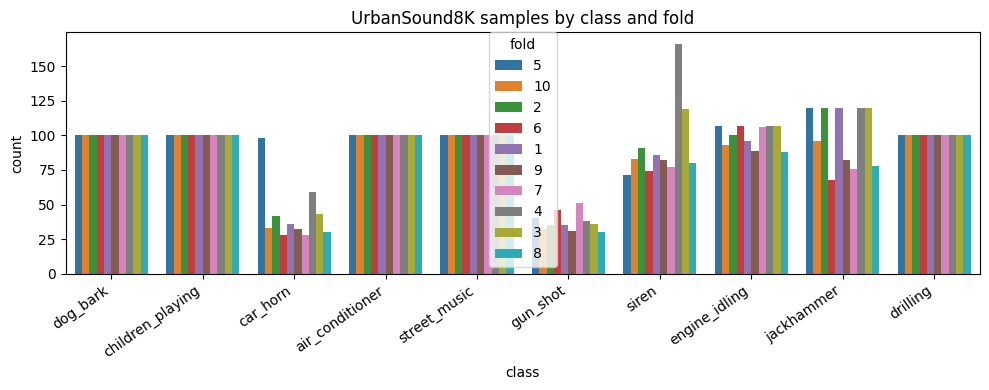

Train class counts:


,count
class,
air_conditioner,600
car_horn,306
children_playing,600
dog_bark,600
drilling,600
engine_idling,624
gun_shot,230
jackhammer,668
siren,607


In [ ]:
plt.figure(figsize=(10,4))
sns.countplot(data=meta, x="class", hue=meta["fold"].astype(str))
plt.xticks(rotation=35, ha="right")
plt.title("UrbanSound8K samples by class and fold")
plt.tight_layout()
plt.show()

print("Train class counts:")
display(train_df["class"].value_counts().sort_index())

## 5) تحميل نموذج YAMNet واستخراج Audio Embeddings

YAMNet نموذج صوتي عميق مدرّب مسبقًا. سنستخدمه لاستخراج embedding بطول 1024 لكل ملف صوتي، ثم ندرب SVM وMLP على الـ embeddings المستخرجة من **كل ملفات train**.

يتم تحويل الصوت إلى mono وبمعدل 16 kHz كما يتطلب YAMNet. يتم حفظ الخصائص في cache حتى لا نعيد استخراجها عند إعادة تشغيل التجارب.

In [ ]:
YAMNET_HANDLE = "https://tfhub.dev/google/yamnet/1"
yamnet = hub.load(YAMNET_HANDLE)
print("YAMNet loaded.")

YAMNet loaded.


In [ ]:
CACHE_DIR = Path("/content/echomind_cache")
CACHE_DIR.mkdir(exist_ok=True)
FEATURE_CACHE = CACHE_DIR / "yamnet_embeddings_full.npz"

def audio_to_yamnet_embedding(path):
    waveform, sr = librosa.load(path, sr=16000, mono=True)
    waveform = waveform.astype(np.float32)
    if waveform.size == 0:
        raise ValueError("Empty audio")
    scores, embeddings, spectrogram = yamnet(tf.convert_to_tensor(waveform, dtype=tf.float32))
    emb = embeddings.numpy()
    return emb.mean(axis=0).astype(np.float32)

def extract_or_load_embeddings(frame, cache_prefix):
    cache_path = CACHE_DIR / f"{cache_prefix}_yamnet.npz"
    if cache_path.exists():
        cached = np.load(cache_path, allow_pickle=True)
        paths = cached["paths"].astype(str)
        X = cached["X"].astype(np.float32)
        y = cached["y"].astype(int)
        if len(paths) == len(frame) and np.array_equal(paths, frame["filepath"].to_numpy(dtype=str)):
            print(f"Loaded cached features: {cache_path}")
            return X, y
        print("Cache does not match current split; rebuilding.")

    features, labels, good_paths, errors = [], [], [], []
    start = time.time()
    for i, row in enumerate(frame.itertuples(index=False), 1):
        try:
            features.append(audio_to_yamnet_embedding(row.filepath))
            labels.append(int(row.classID))
            good_paths.append(row.filepath)
        except Exception as e:
            errors.append((row.filepath, repr(e)))
        if i % 250 == 0 or i == len(frame):
            print(f"{cache_prefix}: {i}/{len(frame)} processed; successful={len(features)}; errors={len(errors)}")

    if errors:
        error_df = pd.DataFrame(errors, columns=["filepath", "error"])
        error_df.to_csv(CACHE_DIR / f"{cache_prefix}_errors.csv", index=False)
        print("Some files failed; see:", CACHE_DIR / f"{cache_prefix}_errors.csv")
        raise RuntimeError(f"{len(errors)} audio files failed. Fix these before reporting full-dataset results.")

    X = np.vstack(features).astype(np.float32)
    y = np.asarray(labels, dtype=int)
    np.savez_compressed(cache_path, X=X, y=y, paths=np.asarray(good_paths))
    print(f"Saved {X.shape} to {cache_path}; elapsed={time.time()-start:.1f}s")
    return X, y

In [ ]:
X_train, y_train = extract_or_load_embeddings(train_df, "train")
X_val, y_val = extract_or_load_embeddings(val_df, "validation")
X_test, y_test = extract_or_load_embeddings(test_df, "test")

print("Shapes:", X_train.shape, X_val.shape, X_test.shape)
assert X_train.shape[0] == len(train_df)
assert X_val.shape[0] == len(val_df)
assert X_test.shape[0] == len(test_df)

train: 250/5435 processed; successful=250; errors=0
train: 500/5435 processed; successful=500; errors=0
train: 750/5435 processed; successful=750; errors=0
train: 1000/5435 processed; successful=1000; errors=0
train: 1250/5435 processed; successful=1250; errors=0
train: 1500/5435 processed; successful=1500; errors=0
train: 1750/5435 processed; successful=1750; errors=0
train: 2000/5435 processed; successful=2000; errors=0
train: 2250/5435 processed; successful=2250; errors=0
train: 2500/5435 processed; successful=2500; errors=0
train: 2750/5435 processed; successful=2750; errors=0
train: 3000/5435 processed; successful=3000; errors=0
train: 3250/5435 processed; successful=3250; errors=0
train: 3500/5435 processed; successful=3500; errors=0
train: 3750/5435 processed; successful=3750; errors=0
train: 4000/5435 processed; successful=4000; errors=0
train: 4250/5435 processed; successful=4250; errors=0
train: 4500/5435 processed; successful=4500; errors=0
train: 4750/5435 processed; succes

## 6) Baseline إضافي: MFCC + SVM

هذا baseline تقليدي للمقارنة. التدريب هنا أيضًا يتم على ملفات train كاملة، وليس على عينة صغيرة.

In [ ]:
MFCC_CACHE = CACHE_DIR / "mfcc_features_full.npz"

def mfcc_feature(path, n_mfcc=40):
    audio, sr = librosa.load(path, sr=22050, mono=True)
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc)
    # Mean + standard deviation over time
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)]).astype(np.float32)

def extract_mfcc_split(frame, name):
    cache = CACHE_DIR / f"{name}_mfcc.npz"
    if cache.exists():
        z = np.load(cache, allow_pickle=True)
        if np.array_equal(z["paths"].astype(str), frame["filepath"].to_numpy(dtype=str)):
            return z["X"].astype(np.float32), z["y"].astype(int)
    feats, labels, paths = [], [], []
    for i, row in enumerate(frame.itertuples(index=False), 1):
        feats.append(mfcc_feature(row.filepath))
        labels.append(int(row.classID))
        paths.append(row.filepath)
        if i % 500 == 0 or i == len(frame):
            print(f"{name}: {i}/{len(frame)}")
    X, y = np.vstack(feats), np.asarray(labels)
    np.savez_compressed(cache, X=X, y=y, paths=np.asarray(paths))
    return X, y

X_train_mfcc, y_train_mfcc = extract_mfcc_split(train_df, "train")
X_val_mfcc, y_val_mfcc = extract_mfcc_split(val_df, "validation")
X_test_mfcc, y_test_mfcc = extract_mfcc_split(test_df, "test")

train: 500/5435
train: 1000/5435
train: 1500/5435
train: 2000/5435


/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1323
  warnings.warn(


train: 2500/5435
train: 3000/5435
train: 3500/5435
train: 4000/5435
train: 4500/5435
train: 5000/5435


/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1103
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1523
  warnings.warn(


train: 5435/5435
validation: 500/838
validation: 838/838
test: 500/2459
test: 1000/2459
test: 1500/2459
test: 2000/2459
test: 2459/2459


## 7) تدريب SVM على YAMNet embeddings

نستخدم Pipeline فيها StandardScaler ثم SVC. نجرب أكثر من إعداد على validation فقط، ونختار الأفضل حسب Macro-F1.

In [ ]:
svm_candidates = [
    {"C": 1, "kernel": "rbf", "gamma": "scale"},
    {"C": 10, "kernel": "rbf", "gamma": "scale"},
    {"C": 30, "kernel": "rbf", "gamma": "scale"},
    {"C": 10, "kernel": "linear"},
]
svm_trials = []
best_svm, best_svm_score, best_svm_params = None, -1, None

for params in svm_candidates:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(**params, class_weight="balanced"))
    ])
    t0 = time.time()
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    acc = accuracy_score(y_val, pred)
    mf1 = f1_score(y_val, pred, average="macro")
    svm_trials.append({**params, "val_accuracy": acc, "val_macro_f1": mf1, "seconds": time.time()-t0})
    print(params, "val_accuracy=", round(acc,4), "val_macro_f1=", round(mf1,4))
    if mf1 > best_svm_score:
        best_svm, best_svm_score, best_svm_params = model, mf1, params

svm_results = pd.DataFrame(svm_trials).sort_values("val_macro_f1", ascending=False)
display(svm_results)
print("Best SVM params:", best_svm_params)

{'C': 1, 'kernel': 'rbf', 'gamma': 'scale'} val_accuracy= 0.7924 val_macro_f1= 0.7926
{'C': 10, 'kernel': 'rbf', 'gamma': 'scale'} val_accuracy= 0.8103 val_macro_f1= 0.8124
{'C': 30, 'kernel': 'rbf', 'gamma': 'scale'} val_accuracy= 0.7864 val_macro_f1= 0.786
{'C': 10, 'kernel': 'linear'} val_accuracy= 0.7589 val_macro_f1= 0.7514


,C,kernel,gamma,val_accuracy,val_macro_f1,seconds
1,10,rbf,scale,0.810263,0.812388,5.740605
0,1,rbf,scale,0.792363,0.792623,8.822383
2,30,rbf,scale,0.786396,0.786012,5.424012
3,10,linear,NaN,0.758950,0.751407,3.959409


Best SVM params: {'C': 10, 'kernel': 'rbf', 'gamma': 'scale'}


## 8) تدريب MLP على YAMNet embeddings

MLP هو Neural Network classifier يتم تدريبه على خصائص YAMNet. نجرّب بنية/إعدادات مختلفة على validation ونختار حسب Macro-F1.

In [ ]:
mlp_candidates = [
    {"hidden_layer_sizes": (256, 128), "alpha": 0.0001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (512, 256), "alpha": 0.0005, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (256, 128), "alpha": 0.001, "learning_rate_init": 0.0005},
]
mlp_trials = []
best_mlp, best_mlp_score, best_mlp_params = None, -1, None

for params in mlp_candidates:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(
            **params, activation="relu", solver="adam",
            batch_size=128, max_iter=100, early_stopping=True,
            validation_fraction=0.12, n_iter_no_change=12,
            random_state=SEED, verbose=False
        ))
    ])
    t0 = time.time()
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    acc = accuracy_score(y_val, pred)
    mf1 = f1_score(y_val, pred, average="macro")
    mlp_trials.append({**params, "val_accuracy": acc, "val_macro_f1": mf1,
                       "iterations": model.named_steps["clf"].n_iter_,
                       "seconds": time.time()-t0})
    print(params, "val_accuracy=", round(acc,4), "val_macro_f1=", round(mf1,4))
    if mf1 > best_mlp_score:
        best_mlp, best_mlp_score, best_mlp_params = model, mf1, params

mlp_results = pd.DataFrame(mlp_trials).sort_values("val_macro_f1", ascending=False)
display(mlp_results)
print("Best MLP params:", best_mlp_params)

{'hidden_layer_sizes': (256, 128), 'alpha': 0.0001, 'learning_rate_init': 0.001} val_accuracy= 0.7661 val_macro_f1= 0.7654
{'hidden_layer_sizes': (512, 256), 'alpha': 0.0005, 'learning_rate_init': 0.001} val_accuracy= 0.7876 val_macro_f1= 0.7812
{'hidden_layer_sizes': (256, 128), 'alpha': 0.001, 'learning_rate_init': 0.0005} val_accuracy= 0.778 val_macro_f1= 0.7704


,hidden_layer_sizes,alpha,learning_rate_init,val_accuracy,val_macro_f1,iterations,seconds
1,"(512, 256)",0.0005,0.0010,0.787589,0.781154,26,22.344945
2,"(256, 128)",0.0010,0.0005,0.778043,0.770402,33,14.730002
0,"(256, 128)",0.0001,0.0010,0.766110,0.765394,29,13.089161


Best MLP params: {'hidden_layer_sizes': (512, 256), 'alpha': 0.0005, 'learning_rate_init': 0.001}


## 9) تدريب MFCC + SVM للمقارنة

In [ ]:
mfcc_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(C=10, kernel="rbf", gamma="scale", class_weight="balanced"))
])
mfcc_svm.fit(X_train_mfcc, y_train_mfcc)
mfcc_val_pred = mfcc_svm.predict(X_val_mfcc)
print("MFCC+SVM validation accuracy:", accuracy_score(y_val_mfcc, mfcc_val_pred))
print("MFCC+SVM validation macro-F1:", f1_score(y_val_mfcc, mfcc_val_pred, average="macro"))

MFCC+SVM validation accuracy: 0.7016706443914081
MFCC+SVM validation macro-F1: 0.6945348276948156


## 10) مقارنة النماذج على Validation واختيار النموذج

نستخدم validation للاختيار فقط. لا نستخدم test في اختيار SVM أو MLP.

In [ ]:
val_comparison = pd.DataFrame([
    {"Model": "MFCC + SVM", "Accuracy": accuracy_score(y_val_mfcc, mfcc_val_pred),
     "Macro-F1": f1_score(y_val_mfcc, mfcc_val_pred, average="macro")},
    {"Model": "YAMNet + SVM", "Accuracy": accuracy_score(y_val, best_svm.predict(X_val)),
     "Macro-F1": f1_score(y_val, best_svm.predict(X_val), average="macro")},
    {"Model": "YAMNet + MLP", "Accuracy": accuracy_score(y_val, best_mlp.predict(X_val)),
     "Macro-F1": f1_score(y_val, best_mlp.predict(X_val), average="macro")},
]).sort_values("Macro-F1", ascending=False)
display(val_comparison)

winner_name = val_comparison.iloc[0]["Model"]
print("Selected model based on validation Macro-F1:", winner_name)

,Model,Accuracy,Macro-F1
1,YAMNet + SVM,0.810263,0.812388
2,YAMNet + MLP,0.787589,0.781154
0,MFCC + SVM,0.701671,0.694535


Selected model based on validation Macro-F1: YAMNet + SVM


## 11) التقييم النهائي على Test

هذه هي النتيجة النهائية على folds 8–10. شغّل هذا الجزء بعد تثبيت الاختيار من validation، ولا تغيّر الإعدادات بناءً على test.

In [ ]:
test_models = {
    "MFCC + SVM": (mfcc_svm, X_test_mfcc, y_test_mfcc),
    "YAMNet + SVM": (best_svm, X_test, y_test),
    "YAMNet + MLP": (best_mlp, X_test, y_test),
}
test_rows = []
test_predictions = {}
for name, (model, X_eval, y_eval) in test_models.items():
    pred = model.predict(X_eval)
    test_predictions[name] = pred
    test_rows.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_eval, pred),
        "Test Macro-F1": f1_score(y_eval, pred, average="macro"),
        "Test Weighted-F1": f1_score(y_eval, pred, average="weighted")
    })
test_results = pd.DataFrame(test_rows).sort_values("Test Macro-F1", ascending=False)
display(test_results)

,Model,Test Accuracy,Test Macro-F1,Test Weighted-F1
2,YAMNet + MLP,0.773078,0.786038,0.767775
1,YAMNet + SVM,0.756812,0.761541,0.754247
0,MFCC + SVM,0.686865,0.705681,0.685096


## 12) Classification Report وConfusion Matrix للنموذج الأفضل

Best test model: YAMNet + MLP
                  precision    recall  f1-score   support

 air_conditioner     0.7191    0.4267    0.5356       300
        car_horn     0.8218    0.8737    0.8469        95
children_playing     0.8491    0.8067    0.8274       300
        dog_bark     0.8485    0.8400    0.8442       300
        drilling     0.8374    0.8067    0.8217       300
   engine_idling     0.6421    0.6444    0.6433       270
        gun_shot     0.9118    1.0000    0.9538        93
      jackhammer     0.6512    0.8242    0.7276       256
           siren     0.9031    0.8367    0.8686       245
    street_music     0.7039    0.9033    0.7912       300

        accuracy                         0.7731      2459
       macro avg     0.7888    0.7962    0.7860      2459
    weighted avg     0.7774    0.7731    0.7678      2459



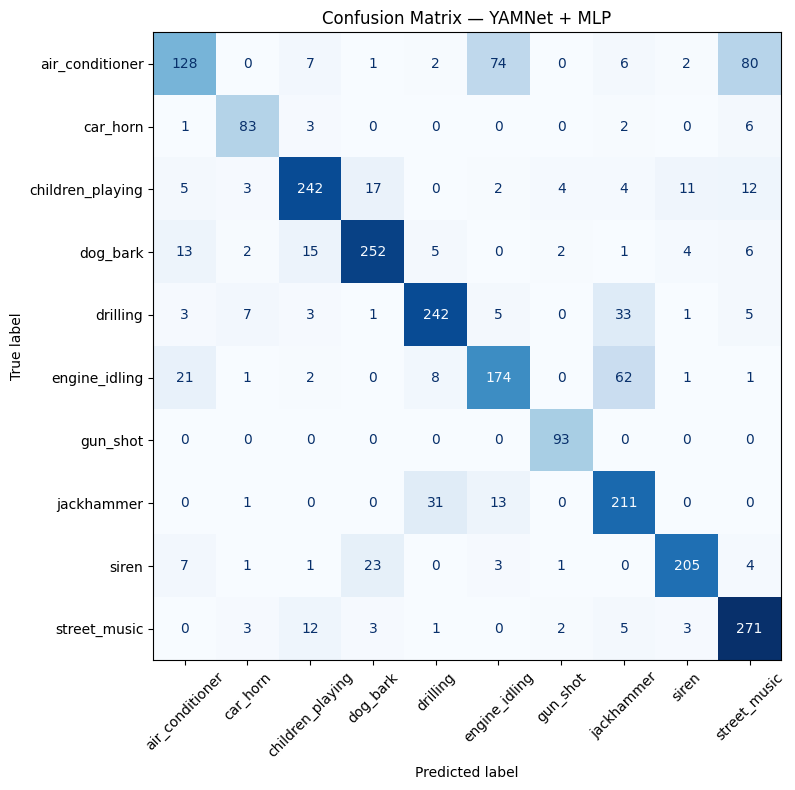

In [ ]:
class_names = [x for x, _ in sorted(meta[["class", "classID"]].drop_duplicates().values, key=lambda z: z[1])]
best_test_name = test_results.iloc[0]["Model"]
best_pred = test_predictions[best_test_name]
print("Best test model:", best_test_name)
print(classification_report(y_test, best_pred, target_names=class_names, digits=4, zero_division=0))

cm = confusion_matrix(y_test, best_pred, labels=list(range(10)))
fig, ax = plt.subplots(figsize=(10,8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title(f"Confusion Matrix — {best_test_name}")
plt.tight_layout()
plt.show()

## 13) حفظ النماذج والنتائج

يتم حفظ SVM وMLP وMFCC-SVM، بالإضافة إلى جداول النتائج والتقارير.

In [ ]:
OUTPUT_DIR = Path("/content/EchoMind_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

joblib.dump(best_svm, OUTPUT_DIR / "yamnet_svm_best.joblib")
joblib.dump(best_mlp, OUTPUT_DIR / "yamnet_mlp_best.joblib")
joblib.dump(mfcc_svm, OUTPUT_DIR / "mfcc_svm.joblib")

val_comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv", index=False)
test_results.to_csv(OUTPUT_DIR / "test_results.csv", index=False)
pd.DataFrame(classification_report(y_test, best_pred, target_names=class_names,
                                   output_dict=True, zero_division=0)).transpose().to_csv(
    OUTPUT_DIR / "best_model_classification_report.csv"
)
with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump({
        "dataset": "UrbanSound8K",
        "total_rows": len(meta),
        "train_folds": [1,2,3,4,5,6],
        "validation_folds": [7],
        "test_folds": [8,9,10],
        "train_samples": len(train_df),
        "validation_samples": len(val_df),
        "test_samples": len(test_df),
        "selected_by_validation_macro_f1": winner_name,
        "best_test_model_for_reporting": best_test_name,
        "svm_params": best_svm_params,
        "mlp_params": {k: list(v) if isinstance(v, tuple) else v for k,v in best_mlp_params.items()}
    }, f, indent=2)
print("Saved outputs to:", OUTPUT_DIR)
print("Files:", [p.name for p in OUTPUT_DIR.iterdir()])

Saved outputs to: /content/EchoMind_outputs
Files: ['mfcc_svm.joblib', 'validation_comparison.csv', 'test_results.csv', 'yamnet_mlp_best.joblib', 'yamnet_svm_best.joblib', 'best_model_classification_report.csv', 'experiment_config.json']


## 14) تنزيل ملفات النتائج من Colab

In [ ]:
!cd /content && zip -qr EchoMind_outputs.zip EchoMind_outputs
from google.colab import files
files.download("/content/EchoMind_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15) واجهة اختيارية لتجربة صوت جديد (ليست بديلًا عن التدريب)

التدريب والتقييم تمّا بالفعل في الأقسام السابقة. هذه الواجهة فقط لتجربة النموذج بعد تدريبه.

In [ ]:
# اختر النموذج الأفضل حسب validation، ثم استخدم نفس نوع الخصائص.
# الواجهة التالية تستخدم YAMNet embeddings + SVM إذا كان هو الفائز؛
# أو YAMNet embeddings + MLP إذا كان هو الفائز.
import gradio as gr

yamnet_winner = best_svm if winner_name == "YAMNet + SVM" else best_mlp

def predict_uploaded_audio(audio_path):
    if audio_path is None:
        return {"Please upload audio": 1.0}
    emb = audio_to_yamnet_embedding(audio_path).reshape(1, -1)
    model = yamnet_winner
    probs = model.predict_proba(emb)[0] if hasattr(model, "predict_proba") else None
    pred_id = int(model.predict(emb)[0])
    if probs is None:
        return {class_names[pred_id]: 1.0}
    return {class_names[i]: float(probs[i]) for i in range(len(class_names))}

demo = gr.Interface(
    fn=predict_uploaded_audio,
    inputs=gr.Audio(type="filepath", label="Upload an audio clip"),
    outputs=gr.Label(num_top_classes=5, label="Predicted sound class"),
    title="EchoMind — UrbanSound8K Sound Classifier",
    description="Model trained on UrbanSound8K. Upload a short audio clip to test it."
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ac47074c04d65d35ca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## ملاحظات مهمة للتقرير والمناقشة

1. اكتبوا أعداد train/validation/test التي ظهرت فعلًا من تشغيل الخلية، ولا تفترضوا أرقامًا إذا تغيّرت نسخة الداتا.
2. لا تكتبوا Accuracy متوقعة. استخدموا النتائج الفعلية التي ستظهر بعد التشغيل.
3. YAMNet شبكة عميقة pretrained لاستخراج الخصائص؛ SVM وMLP هما المصنفان اللذان تم تدريبهما على بيانات UrbanSound8K.
4. MFCC + SVM baseline تقليدي للمقارنة.
5. هذا التقسيم حسب folds يحافظ على الفصل بين folds، لكنه لا يعني بالضرورة أن كل تسجيلات العالم أو كل ظروف التسجيل مستقلة تمامًا.
6. إذا ظهر خطأ أثناء تنزيل الأرشيف، لا تكملوا على ملف ناقص. احذفوا `/content/UrbanSound8K.tar.gz` وأعيدوا التنزيل، أو استكملوه باستخدام `wget -c`.